# Part 1(a): DCGAN on MNIST

A convolutional GAN trained on MNIST for 50 epochs: model design, training procedure, training diagnostics, generated samples and latent-space interpolation.


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np
import matplotlib.pyplot as plt
import warnings, os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 1
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available()
                      else 'cpu')

In [3]:
# Hyperparameters

LATENT_DIM      = 100    
IMG_CHANNELS    = 1      
IMG_SIZE        = 28     
BATCH_SIZE      = 128
NUM_EPOCHS      = 50
LR_G            = 2e-4   
LR_D            = 4e-4   
BETA1           = 0.5    
SAMPLE_INTERVAL = 10      # Save samples every 10 epochs



In [4]:
# Data Loading & Processing

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])   # scale pixels 
])

train_dataset = datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)
import multiprocessing
num_workers = min(4, multiprocessing.cpu_count())
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=num_workers, pin_memory=True if torch.cuda.is_available() else False
)


## Transformation Map

The transformation map is represented by the Generator in GAN. Its purpose is to map from the latent space to the high dimensional data distribution in this case the image space such that 
the transformation map $G_\theta: \mathcal{Z} \to \mathcal{X}$ is defined as:
$$ x_{fake} = G_\theta(z) $$

Where the latent space $\mathcal{Z} = \mathbb{R}^{100}$ is a noise vector sampled from a normal distribution $z \sim \mathcal{N}(0, I)$. Additionally $\mathcal{X} \in [-1, 1]^{1 \times 28 \times 28}$ is the image space representing the greyscale digits. Lastly $\theta$ is the 1,948,545 parameters of the generator.

Its objective is to push the simple normal prior to an implicit distribution $p_g$ over images such that after the training $p_g \approx p_{\text{data}}$.

The generator is a CNN which uses transposed convolution layers to upsample the low dimension of the noise vector to the dimension of the image space. The architecture is:

1. A fully connected layer that projects the 100 dimension $z$ into a 12,544 dimensional space. Followed by a 1D batch Normalization and a ReLU activation and then the 12,544 vector is rearranged into a 3D tensor (256,7,7). This layer has 1,266,944 params (100×12544 weights + 12544 bias) for the linear and 25,088 params (12544 $\gamma $ + 12544 $\beta $) for the batch normalization.

2. The first upsampling layer uses ConvTranspose2d to upsample from 256 channels to 128 with a kernel size of 4, stride 2 and padding 1 resulting in a feature map (128, 14, 14) which is then passed by a batch normalization and ReLU. This layer has 524,416 params (256×128×4×4 weights + 128 bias) for the transpose convolution and 256 params (128 $\gamma $ + 128 $\beta $) for the batch normalization.

3. The second upsampling layer uses ConvTranspose2d to upsample from 128 channels to 64 with a kernel size of 4, stride 2 and padding 1 resulting in a feature map (64, 28, 28) which is then passed by a batch normalization and ReLU. This layer has 131,136 params (128×64×4×4 weights + 64 bias) for the transpose convolution and 128 params (64 $\gamma $ + 64 $\beta $) for the batch normalization.

4. A convolutional layer that maps from the 64 channels to 1 channel by a kernel of size 3, stride 1 and padding 1, resulting in a feature map (1, 28, 28). This layer has 577 params (64×1×3×3 weights + 1 bias)

5. A final Tanh activation to scale pixel to [-1,1]

The transformation map can be thus expressed as:
$$ G_\theta(z) = \tanh(\text{Conv}_{2d}(\text{ReLU}(\text{BN}(\text{ConvT}_{2d}(\text{ReLU}(\text{BN}(\text{ConvT}_{2d}(\text{ReLU}(\text{BN}(\text{Linear}(z))))))))))) $$

So the total amount of parameters is 1,948,545.

The discriminator architecture is: 
1. A convolutional layer that maps from 1 to 64 channels by a kernel of size 4, stride 2, and padding 1 resulting in a feature map (64, 14, 14) which is then passed by LeakyReLU activation ($\alpha = 0.02$). This layer has 1,088 parameters (1×64×4×4 weights + 64 bias)

2. A convolutional layer that maps from 64 to 128 channels by a kernel of size 4, stride 2, and padding 1 resulting in a feature map (128, 7, 7) which is then passed by Batch Normalization and LeakyReLU activation ($\alpha = 0.02$). This layer has 131,200 parameters (64×128×4×4 weights + 128 bias) for Conv2d and  for the Batch Normalizatio 256 params (128 $\gamma $ + 128 $\beta $)

3. A flattening layer that reshapes the feature map into a vector of size 6,272 (6,272 = 128 x 7 x 7)

4. A fully connected layer that projects the vector of dimension 6,272 into a real number followed by a sigmoid activation. This layer has 6,273 parameters (6,272 weights + 1 bias)


In [5]:
# Generator 
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.project = nn.Sequential(
            nn.Linear(latent_dim, 256 * 7 * 7),
            nn.BatchNorm1d(256 * 7 * 7),
            nn.ReLU(True),
        )
        self.conv_blocks = nn.Sequential(
            # 256x7x7 to 128x14x14
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 128x14x14 to 64x28x28
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 64x28x28 to 1x28x28
            nn.Conv2d(64, IMG_CHANNELS, kernel_size=3, stride=1, padding=1),
            nn.Tanh(),  # output in -1, 1
        )

    def forward(self, z):
        x = self.project(z)         
        x = x.view(-1, 256, 7, 7)   
        return self.conv_blocks(x)   


# Discriminator 
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # 1x28x28 to 64x14x14
            nn.Conv2d(IMG_CHANNELS, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # 64x14x14 to 128x7x7
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),  
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


# Send to devicce
G = Generator().to(device)
D = Discriminator().to(device)


## Training Procedure

The GAN is trained by solving a minmax game between the generator and the discriminator. The objective is to minimize the BCE loss: 

$$ \min_G \max_D V(D, G) = \mathbb{E}_{x \sim p_{data}} [\log D_\phi(x)] + \mathbb{E}_{z \sim p_z} [\log(1 - D_\phi(G_\theta(z)))] $$

In the training we initially update the discriminator, whos roll is to identify whether an image is generated or real. To prevent the discriminator from being overconfident we applied a one side label smothing that is real labels are set to 0.9 instead of 1 while keeping fakes at 0.

$$ \mathcal{L}_D = \text{BCE}(D_\phi(x_{real}), 0.9) + \text{BCE}(D_\phi(x_{fake}\text{.detach}()), 0.0) $$

In this step we only update the discriminator thus fake images are detached so theyre treades as constant ensuring the generator does not update.

1. Sample a mini-batch of real images $x_i$, sample noise $z_i$ and produce fake images $G_\theta(z_i)$. 
2. Compute discriminator loss $\mathcal{L}_D$
3. Update $\phi$ using Adam


We then update the generator, which we prevent the vanishing gradients at the beggining by maximizing $\log D$ instead of the true objective of minimizing $\log(1 - D)$. It maximizes $\log D$ by treating fake images as if they are real.
$$ \mathcal{L}_G = \text{BCE}(D_\phi(G_\theta(z)), 1.0) $$

Both are optimized using Adam ($\beta_1 = 0.5, \beta_2 = 0.999$). For the learning rate we set a higher lr for the distrciminator ($4 \times 10^{-4}$) than the generator ($2 \times 10^{-4}$) to ensure the discriminiator converges faster and can provide reliable gradient so the generator improves. 

In [6]:
# Training Loop
criterion = nn.BCELoss().to(device)
opt_G = optim.Adam(G.parameters(), lr=LR_G, betas=(BETA1, 0.999))
opt_D = optim.Adam(D.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Fixed noise 
fixed_noise = torch.randn(64, LATENT_DIM, device=device)

# Storage of losses and sample images
history = {'d_loss': [], 'g_loss': [], 'd_real_prob': [], 'd_fake_prob': [], 'd_grad_norm': [], 'g_grad_norm': []}
sample_images = {}  # epoch -> tensor grid

for epoch in range(1, NUM_EPOCHS + 1):
    d_loss_epoch = 0.0
    g_loss_epoch = 0.0
    d_real_prob_epoch = 0.0
    d_fake_prob_epoch = 0.0
    d_grad_norm_epoch = 0.0
    g_grad_norm_epoch = 0.0

    for real_imgs, _ in train_loader:
        batch = real_imgs.size(0)
        real_imgs = real_imgs.to(device)

        # one sided label smoothing
        real_label_D = torch.full((batch, 1), 0.9, device=device)  # real = 0.9
        fake_label_D = torch.zeros(batch, 1, device=device)        # fake = 0.0

        # Train Discriminator 
        z = torch.randn(batch, LATENT_DIM, device=device)
        fake_imgs = G(z).detach()

        d_real = D(real_imgs)
        d_fake = D(fake_imgs)

        loss_D = criterion(d_real, real_label_D) + criterion(d_fake, fake_label_D)

        opt_D.zero_grad()
        loss_D.backward()
        opt_D.step()

        # Calculate D gradient norm
        d_norm = 0.0
        for p in D.parameters():
            if p.grad is not None:
                d_norm += p.grad.data.norm(2).item() ** 2
        d_norm = d_norm ** 0.5

        # Train Generator 
        z = torch.randn(batch, LATENT_DIM, device=device)
        fake_imgs = G(z)
        d_fake = D(fake_imgs)

        real_label_G = torch.ones(batch, 1, device=device)
        loss_G = criterion(d_fake, real_label_G)  

        opt_G.zero_grad()
        loss_G.backward()
        opt_G.step()

        # Calculate G gradient norm
        g_norm = 0.0
        for p in G.parameters():
            if p.grad is not None:
                g_norm += p.grad.data.norm(2).item() ** 2
        g_norm = g_norm ** 0.5

        d_loss_epoch += loss_D.item()
        g_loss_epoch += loss_G.item()
        d_real_prob_epoch += torch.sigmoid(d_real).mean().item()
        d_fake_prob_epoch += torch.sigmoid(d_fake).mean().item()
        d_grad_norm_epoch += d_norm
        g_grad_norm_epoch += g_norm

    n_batches = len(train_loader)
    history['d_loss'].append(d_loss_epoch / n_batches)
    history['g_loss'].append(g_loss_epoch / n_batches)
    history['d_real_prob'].append(d_real_prob_epoch / n_batches)
    history['d_fake_prob'].append(d_fake_prob_epoch / n_batches)
    history['d_grad_norm'].append(d_grad_norm_epoch / n_batches)
    history['g_grad_norm'].append(g_grad_norm_epoch / n_batches)

    # Save sample images at intervals
    if epoch == 1 or epoch % SAMPLE_INTERVAL == 0 or epoch == NUM_EPOCHS:
        G.eval()
        with torch.no_grad():
            gen = G(fixed_noise).cpu()
        G.train()
        sample_images[epoch] = gen



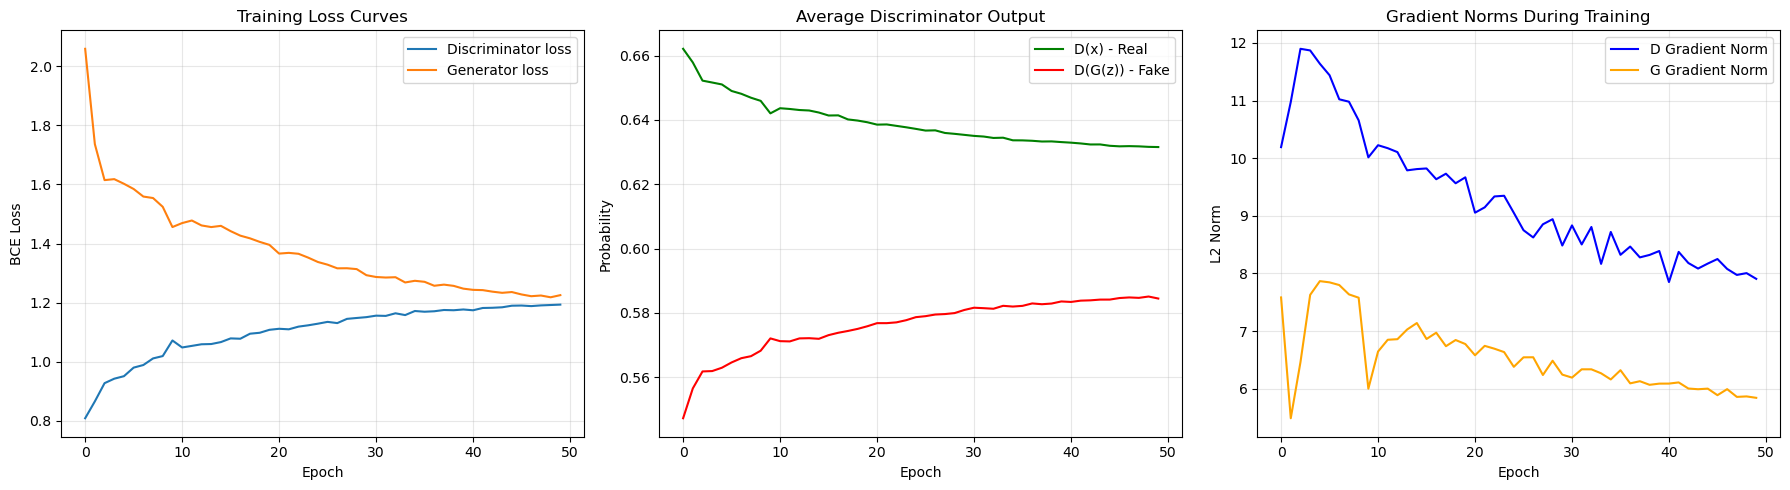

In [7]:
# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Loss Curves
axes[0].plot(history['d_loss'], label='Discriminator loss', linewidth=1.5)
axes[0].plot(history['g_loss'], label='Generator loss', linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Training Loss Curves')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Discriminator Probabilities 
axes[1].plot(history['d_real_prob'], label='D(x) - Real', linewidth=1.5, color='green')
axes[1].plot(history['d_fake_prob'], label='D(G(z)) - Fake', linewidth=1.5, color='red')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Probability')
axes[1].set_title('Average Discriminator Output')
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Gradient Norms
axes[2].plot(history['d_grad_norm'], label='D Gradient Norm', linewidth=1.5, color='blue')
axes[2].plot(history['g_grad_norm'], label='G Gradient Norm', linewidth=1.5, color='orange')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('L2 Norm')
axes[2].set_title('Gradient Norms During Training')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


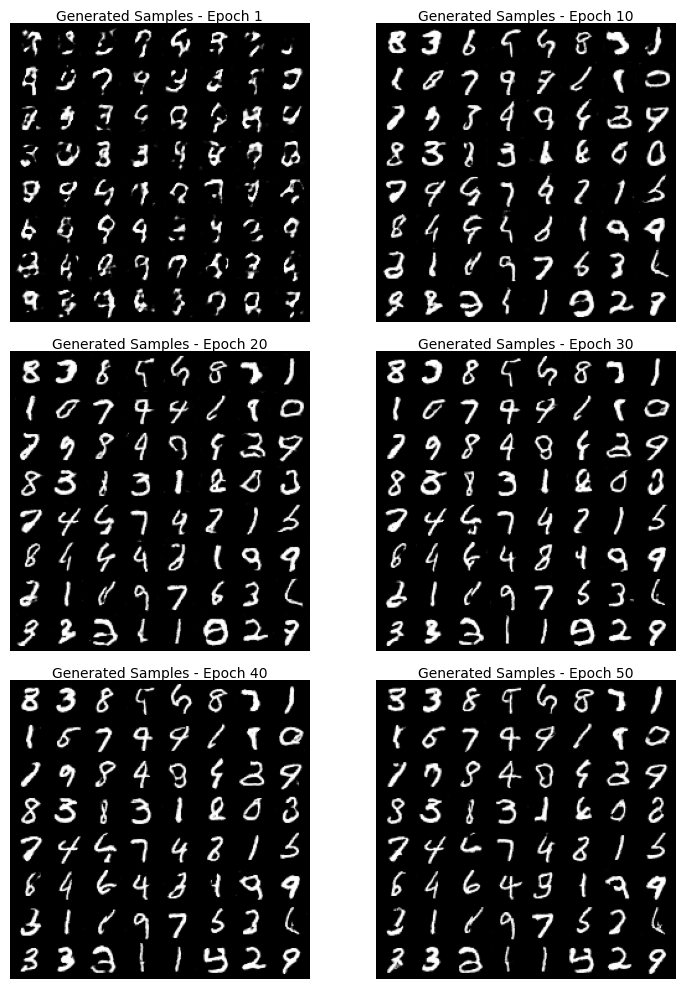

In [8]:
# Intermediate & Final Generated Samples

def show_compact_grid(sample_images, nrows=3, ncols=2):
    sorted_epochs = sorted(sample_images.keys())
    fig, axes = plt.subplots(nrows, ncols, figsize=(8, 10))
    axes = axes.flatten()  # Flatten for easy iteration

    for i, ep in enumerate(sorted_epochs):
        grid = make_grid(sample_images[ep], nrow=8, normalize=True, value_range=(-1, 1))
        axes[i].imshow(grid.permute(1, 2, 0).numpy(), cmap='gray')
        axes[i].set_title(f'Generated Samples - Epoch {ep}', fontsize=10, pad=2)
        axes[i].axis('off')


    plt.subplots_adjust(wspace=0, hspace=0)
    plt.tight_layout()
    plt.show()

show_compact_grid(sample_images)




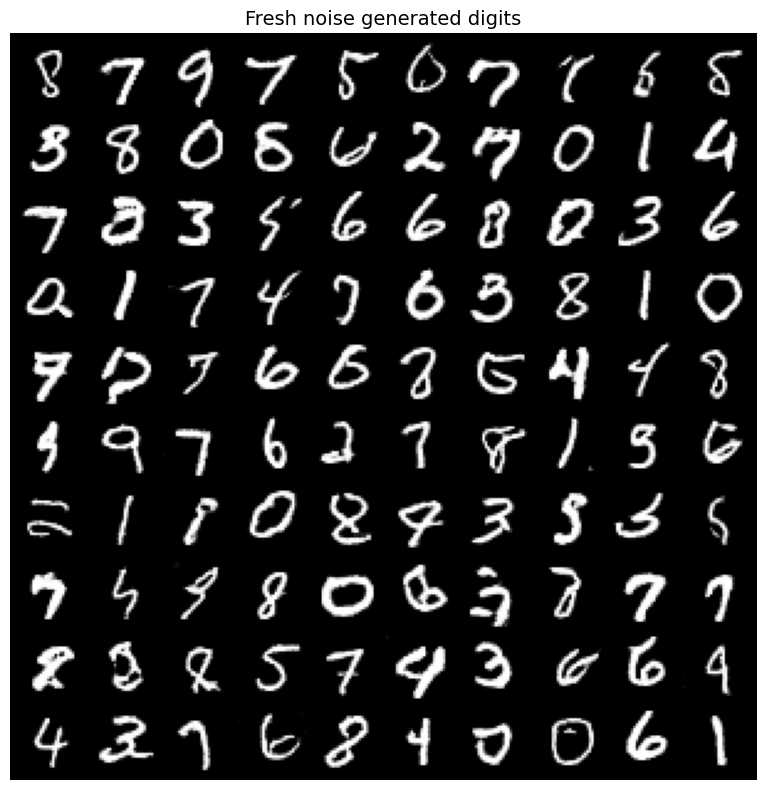

In [10]:
# Final Samples
G.eval()
with torch.no_grad():
    z_fresh = torch.randn(100, LATENT_DIM, device=device)
    final_samples = G(z_fresh).cpu()
G.train()


def show_grid(tensor, title, nrow=8):
    grid = make_grid(tensor, nrow=nrow, normalize=True, value_range=(-1, 1))
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap='gray')
    plt.title(title, fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

show_grid(final_samples, 'Fresh noise generated digits', nrow=10)

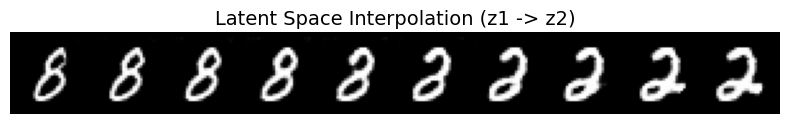

In [ ]:
# Latent Space Interpolation

G.eval()
n_interp = 10  # steps between two endpoints

z1 = torch.randn(1, LATENT_DIM, device=device)
z2 = torch.randn(1, LATENT_DIM, device=device)

alphas = torch.linspace(0, 1, n_interp, device=device).unsqueeze(1)
z_interp = z1 * (1 - alphas) + z2 * alphas

with torch.no_grad():
    interp_imgs = G(z_interp).cpu()
G.train()

show_grid(interp_imgs, 'Latent Space Interpolation (z1 -> z2)', nrow=n_interp)

### Evaluation of generator:

1. At the start it is clear the generator has not learned the data distribution, the image is random white blobs this is also reflected in the low discriminator loss (0.7) while having an extremely high generator loss (2.1) showing $D_\phi$ easily detects the fakes.

2. By epoch 5 certain number structures are recognizable while still blurry some silhouettes emerge. By epoch 20 numbers are clearly recognizable, which the diagnostic plots confirm with the probabilities converging towards an equilibrium, as the generator is learning how to fool the discriminator.

3. The GAN has a stable training with a converging loss. From the the right plot we can see a stable with the gradients declining smoothly without severe jumps, similarly with the Loss graph, the losses converge steadily without significant jumps.

### Improvements
The current DCGAN effectively generates digits, however we can improve it by:

1. Currently hyperparameters are based on the literature defaults so an improvement is to specifically tune batch size, with learning rate for more stable gradients and smoother BatchNorm for this particular GAN. Additionally exploring increasing the latent dimension to improve the representational capacity of the model. A key improvement is tuning the hyperparameters by conducting a grid search over lr, batch size and latent dimension to find the optimal hyperparameters for the GAN.

2. We can replace the BCE loss with Wasserstein-1 distance (EM) and a gradient penalty, then the objective function is continuous and differentiable everywhere. Additionally the discriminator outputs an unbounded number which helps stabilize the min-max game. The EM distance directly correlates with the sample quality providing a meaningful loss curve for monitoring the convergence.

3. We can change the ConvTranspose2d with pixel shuffle upsampling to prevent the checkerboard artifacts that come with the ConvTranspose2d.
